# Postprocessing

In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
import h5py
import numpy as np
import pandas as pd
from matplotlib.patches import Circle
import os
import TM26_unet as unet
from scipy.interpolate import RectBivariateSpline

GPU = True
MULTIGPU = True

DELETE_OLD_FILES = False

SMALL_SIZE = 18
MEDIUM_SIZE = 22
BIGGER_SIZE = 24
GPU = True
diffLimDir = "dataInputs/"
testDataDir = "output_prep/"
outputDir = "output_post/"
inputDir = "output_infer/"


## load data

In [2]:
with h5py.File(inputDir+"predictions.h5", 'r') as temp:
    inference = temp[list(temp.keys())[0]][()]
    
with h5py.File(testDataDir+"ao_psf_test_1.h5", 'r') as temp:
    key = list(temp.keys())
    tempData = temp[key[0]][()][:]
    truth = np.zeros((tempData.shape[0], 270, 270))
    for i in range(tempData.shape[0]):
        truth[i] = unet.pixel_adder(tempData[i], final_shape=[270, 270])

In [3]:
with h5py.File(diffLimDir+"ipsf_difflim.h5", 'r') as temp:
    key = list(temp.keys())
    ipsf_difflim = unet.pixel_adder(temp[key[0]][()][:], final_shape=[270, 270])

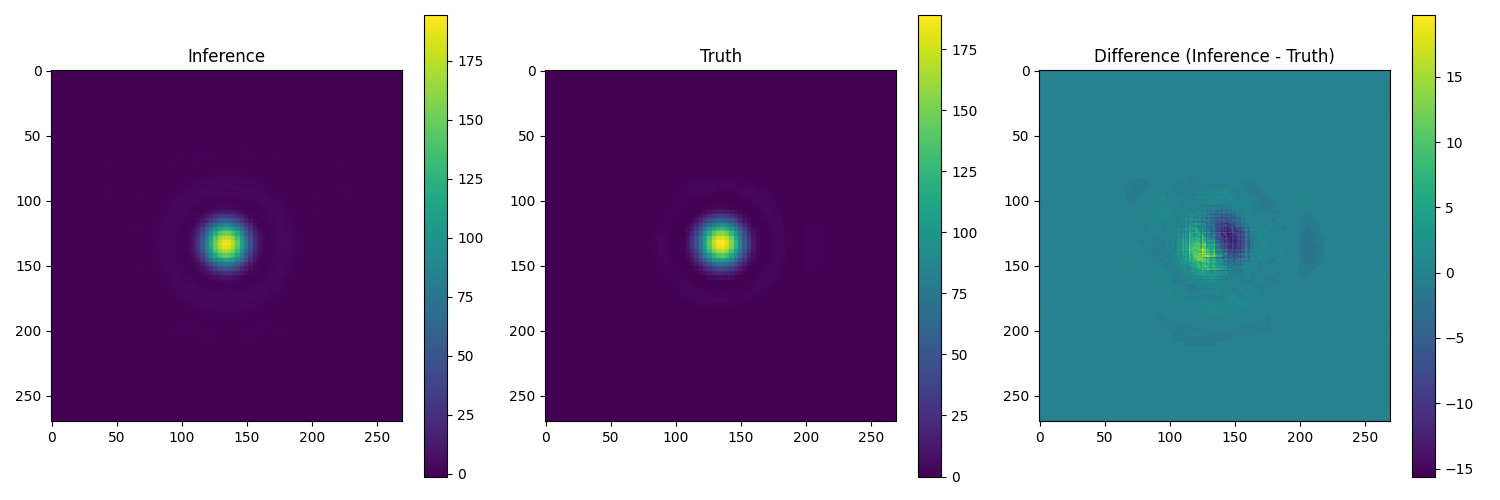

In [7]:
plt.close('all')
fig, axes = plt.subplots(1, 3, figsize=(15, 5))


im0 = axes[0].imshow(inference[0])
axes[0].set_title('Inference')
fig.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(truth[0])
axes[1].set_title('Truth')
fig.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(inference[0] - truth[0])
axes[2].set_title('Difference (Inference - Truth)')
fig.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()

## Strehl

Images do not have a center pixel. Its value must be interpolated. ie. bilinear or bicubic interpolation. If there are enough pixels -> bicubic

In [5]:
height, width = ipsf_difflim.shape
# Center coordinates
center_x = (width - 1) / 2  # 49.5
center_y = (height - 1) / 2  # 39.5

spline = RectBivariateSpline(np.arange(height), np.arange(width), ipsf_difflim, kx=3, ky=3)
center_value_difflim = spline(center_y, center_x)[0, 0]


interpolation_strehl = np.zeros(inference.shape[0])
truth_strehl = np.zeros(truth.shape[0])

for i in range(inference.shape[0]):
    spline = RectBivariateSpline(np.arange(height), np.arange(width), inference[i,:,:], kx=3, ky=3)
    interpolation_strehl[i] = spline(center_y, center_x)[0, 0]/center_value_difflim
    spline = RectBivariateSpline(np.arange(height), np.arange(width), truth[i], kx=3, ky=3)
    truth_strehl[i] = spline(center_y, center_x)[0, 0]/center_value_difflim

relative_strehl_dist = (interpolation_strehl - truth_strehl) / truth_strehl

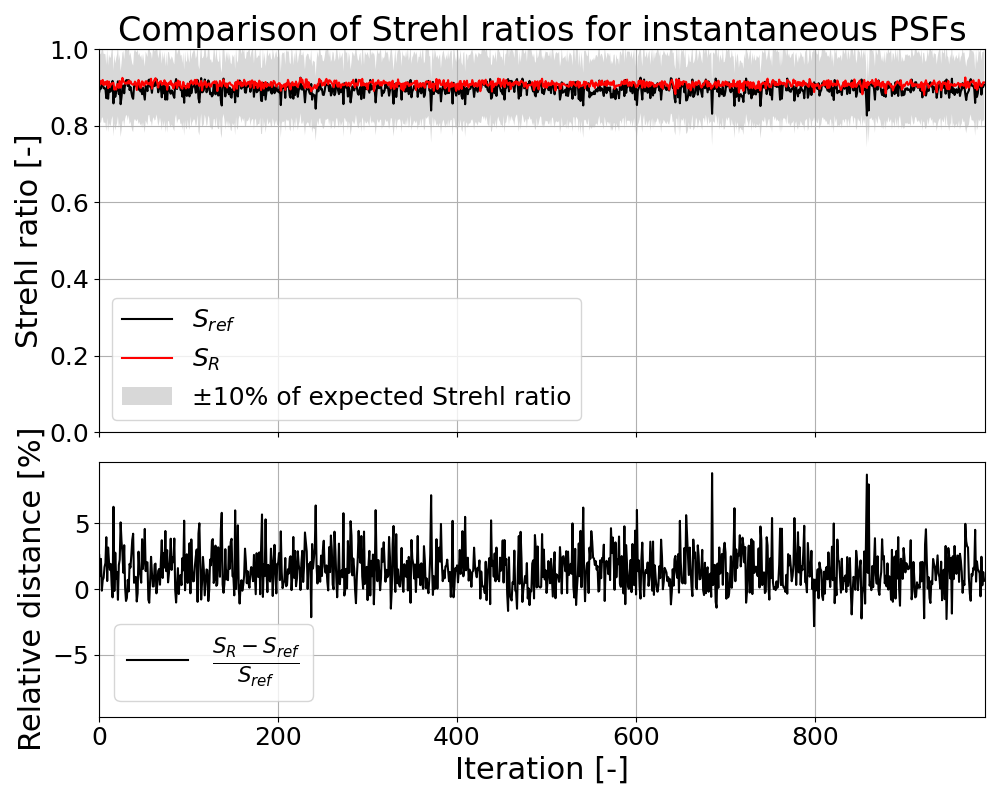

In [6]:
lower_bound = truth_strehl * 0.9  # -10%
upper_bound = truth_strehl * 1.1  # +10%

plt.close('all')
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [3, 2]})

# Top plot: Strehl ratios
ax.plot(truth_strehl, 'k', label=r'$S_{ref}$')
ax.plot(interpolation_strehl, 'r', label=r'$S_{R}$')
ax.set_ylim([0, 1])
ax.fill_between(range(len(truth_strehl)), lower_bound, upper_bound, 
                color='gray', alpha=0.3, edgecolor='none', label='±10% of expected Strehl ratio')
ax.set_ylabel('Strehl ratio [-]', fontsize=MEDIUM_SIZE)
ax.tick_params(axis='y', labelsize=SMALL_SIZE)
ax.legend(fontsize=SMALL_SIZE)
ax.set_title("Comparison of Strehl ratios for instantaneous PSFs", fontsize=BIGGER_SIZE)
ax.set_xlim([0, inference.shape[0]])
ax.grid()

# Bottom plot: Relative distance (ax2 is now a separate subplot below)
ax2.plot(relative_strehl_dist * 100, 'k', label=r"$\frac{S_{R}-S_{ref}}{S_{ref}}$")
ax2.set_ylabel('Relative distance [%]', fontsize=MEDIUM_SIZE, color='k')
ax2.tick_params(axis='y', labelsize=SMALL_SIZE, colors='k')
symetric_lim = max(abs(np.min(relative_strehl_dist) * 110), abs(np.max(relative_strehl_dist) * 110))
ax2.set_ylim([-symetric_lim, symetric_lim])
ax2.legend(fontsize=MEDIUM_SIZE)
ax2.set_xlabel('Iteration [-]', fontsize=MEDIUM_SIZE)
ax2.set_xlim([0, inference.shape[0]])
ax2.grid()
ax2.tick_params(axis='x', labelsize=SMALL_SIZE)

plt.tight_layout()
plt.show()

## FWMH

1. Find max
2. Find FWMH
3. Compare (+/- 10%)

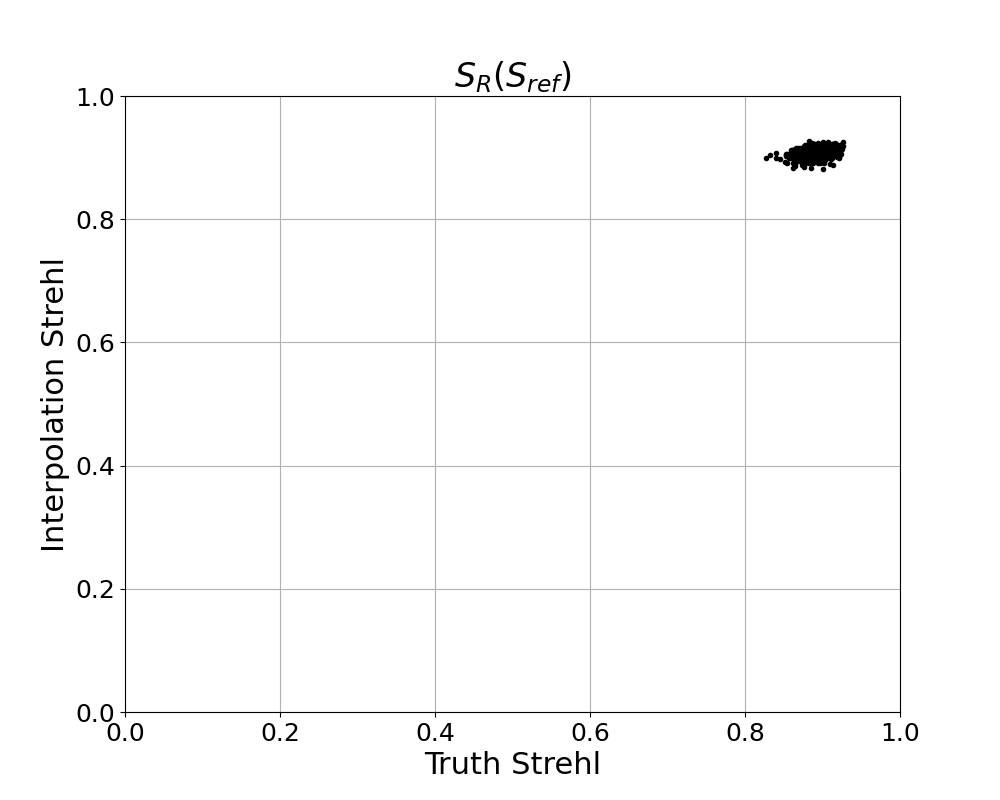

In [17]:
plt.close('all')
plt.figure(figsize=(10, 8))
plt.plot(truth_strehl,interpolation_strehl,'.k')
plt.xlim([0,1])
plt.ylim([0,1])
plt.xlabel('Truth Strehl', fontsize=MEDIUM_SIZE)
plt.ylabel('Interpolation Strehl', fontsize=MEDIUM_SIZE)
plt.xticks(fontsize=SMALL_SIZE)
plt.yticks(fontsize=SMALL_SIZE)
plt.title(r'$S_R(S_{ref})$', fontsize=BIGGER_SIZE)
plt.grid(True)
plt.show()

## Rotational average

1. Find center
2. Average the PSF
3. compare